# Short-Term Indoor CO2 Prediction for Ventilation Monitoring

## 1. Engineering problem and aims
Indoor CO2 forecasting can provide an early warning that ventilation may not be keeping pace with indoor sources. This project asks how accurately the selected MSI sensor can predict measured CO2 approximately 20 minutes ahead. The intended use is decision support for ventilation monitoring, not automatic control or a health-threshold decision.

## 2. Dataset and inputs/outputs
The environmental CSV contains JSON-packed sensor readings, while the occupancy CSV and location workbook provide supporting data. The implemented model uses CO2 in ppm, temperature in °C, source humidity units, historical CO2 and a rate feature. Occupancy is deferred because the available room mapping is marked incorrect or unresolved; joining it could associate people counts with the wrong environmental sensor. The forecast output is the measured CO2 value approximately 20 minutes after each issue time.

In [1]:
"""Import the pandas and JSON dependencies used by the workflow."""

from pathlib import Path
import json
import pandas as pd

In [2]:
"""Locate the raw dataset folder and load environmental records.

Inputs are the named CSV files and optional location workbook. Sensor IDs
remain strings; database timestamps are UTC. Occupancy is deferred by default.
NROWS=None loads all environmental records. Raises FileNotFoundError if the
folder is absent; a missing Excel reader skips only location metadata."""

# Search upward as well as the current folder so the notebook is portable.
DATA_FOLDER = "MMA3001 Dataset - MSI Occupancy and Environmental"
search_locations = [Path.cwd(), *Path.cwd().parents]
data_dir = next((p / DATA_FOLDER for p in search_locations if (p / DATA_FOLDER).is_dir()), None)
if data_dir is None:
    raise FileNotFoundError(f"Could not find {DATA_FOLDER!r} from {Path.cwd()}")

# These names are part of the reproducible raw-data folder contract.
occupancy_path = data_dir / "5occupancySensor_MayToDec2024_9MRows.csv"
environment_path = data_dir / "5EnvSensor_MayToDec2024_180kRows.csv"
locations_path = data_dir / "Sensor ID and Locations.xlsx"

# Set to a row count (e.g. 10_000) for a quick preview; None loads all rows.
NROWS = None
# Occupancy is intentionally deferred because its room mapping is unresolved.
LOAD_OCCUPANCY = False
occupancy = pd.read_csv(
    occupancy_path, nrows=NROWS,
    dtype={"deviceid": "string", "floorspaceid": "string"},
) if LOAD_OCCUPANCY else None
environment = pd.read_csv(
    environment_path, nrows=NROWS, dtype={"sensorid": "string"},
)
# UTC keeps timestamps comparable across daylight-saving offsets.
for column in ["collecteddate", "occupancystatuschangedate"]:
    if occupancy is not None:
        occupancy[column] = pd.to_datetime(occupancy[column], format="mixed", utc=True)
# Parse database timestamps as UTC; measurement timestamps are extracted from JSON below.
for column in ["createdate", "processdate"]:
    environment[column] = pd.to_datetime(environment[column], format="mixed", utc=True)

if not locations_path.exists():
    raise FileNotFoundError(
        f"Required location workbook not found: {locations_path}"
    )

# Keep both workbook sheets, including the occupancy sheet's original warning.
# Read all workbook sheets so the original occupancy-mapping warning is retained.
try:
    location_sheets = pd.read_excel(locations_path, sheet_name=None, dtype="string")
except ImportError:
    location_sheets = {}
    print("Location workbook skipped. To enable it, run %pip install openpyxl in this kernel.")
locations = location_sheets.get("ENV", pd.DataFrame())
occupancy_locations = location_sheets.get("OCC (Incorrect Data - SpaceFloo", pd.DataFrame())

print(f"Data folder: {data_dir}")
print(f"Occupancy: {occupancy.shape if occupancy is not None else 'deferred'}")
print(f"Environment: {environment.shape}")
for sheet_name, sheet in location_sheets.items():
    print(f"Locations [{sheet_name}]: {sheet.shape}")
display(environment.head(), locations.head())

Data folder: c:\Users\ezhu2\Documents\MMA3001\MMA3001-Eric-Zhu\MMA3001 Dataset - MSI Occupancy and Environmental
Occupancy: deferred
Environment: (179447, 8)
Locations [ENV]: (78, 6)
Locations [OCC (Incorrect Data - SpaceFloo]: (89, 7)


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-28 16:11:58.210358+00:00,2024-02-28 16:11:58.210358+00:00
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 06:09:08.833822+00:00,2024-02-29 06:09:08.833822+00:00
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 06:09:12.444245+00:00,2024-02-29 06:09:12.444245+00:00
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 06:10:24.443407+00:00,2024-02-29 06:10:24.443407+00:00
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 06:11:11.348578+00:00,2024-02-29 06:11:11.348578+00:00


,Building,Floor/Room,Area,Physical Label,Sensor,ID
0,60,1-PS01,Corridor,ES1104,Env,6012003000486
1,69,1-PS02,Breakout,ES2113,Env,6012003000882
2,60,1.40,Board Room,ES1102,Env,6012003000462
3,60,1.41,Open Office,ES1110,Env,6012003000424
4,60,1.41A,Focus Room 1,ES1101,Env,6012003000448


## 3. Data cleaning and exploration
Use the measurement times inside JSON, rather than database creation times. Remove exact repeated measurements; exclude conflicting values at the same sensor/time/variable instead of choosing one arbitrarily. No interpolation or target filling is used. Nonpositive CO2 is excluded; other unusual values remain for inspection.

In [3]:
"""Extract measured CO2, temperature and humidity from environmental JSON.

Produces co2 with UTC measurement timestamps, ppm, degrees Celsius and the
source humidity units. Invalid rows, exact duplicates, conflicting keys and
nonpositive CO2 are audited and excluded. No values are interpolated."""

from time import perf_counter
import numpy as np
from co2_models import clean_environment_readings, extract_environment_measurements
# Time parsing separately so the preprocessing cost can be reported.
started = perf_counter()
records, parse_errors = [], []
# Each raw row contains JSON; keep malformed rows in an audit list instead of stopping the full run.
for row in environment.itertuples(index=False):
    try:
        records.extend(extract_environment_measurements(row.jsondata, row.sensorid))
    except (ValueError, TypeError, AttributeError) as exc:
        parse_errors.append((row.id, str(exc)))
# Convert the extracted tuples into a long table before duplicate/conflict cleaning.
readings = pd.DataFrame(records, columns=["sensorid", "timestamp", "variable", "value"])
# The tested helper removes exact duplicates, excludes conflicting keys and rejects invalid CO2.
co2, cleaning_summary = clean_environment_readings(readings)
print({"JSON errors": len(parse_errors), **cleaning_summary})
print(f"Parsing and cleaning: {perf_counter() - started:.2f} seconds")
display(co2.head(), co2[["co2_ppm", "Temperature", "Humidity"]].describe())

{'JSON errors': 0, 'invalid readings': 0, 'exact duplicates removed': 409812, 'conflicting readings excluded': 0, 'nonpositive CO2 excluded': 0}
Parsing and cleaning: 5.42 seconds


variable,sensorid,timestamp,co2_ppm,Humidity,Temperature
0,6012002000227,2023-12-11 05:07:53+00:00,666.0,69.0,24.0
1,6012002000241,2023-12-11 05:52:45+00:00,603.0,66.0,23.8
2,6012002000241,2025-05-19 13:08:04+00:00,447.0,45.0,15.5
3,6012002000326,2023-12-11 05:00:57+00:00,525.0,68.0,23.8
4,6012002000326,2025-09-07 10:09:30+00:00,410.0,60.0,19.0


variable,co2_ppm,Temperature,Humidity
count,42843.000000,42843.000000,42843.000000
mean,451.695750,21.553906,50.958663
std,34.378194,3.459916,10.148825
min,400.000000,11.800000,17.000000
25%,431.000000,19.000000,44.000000
50%,443.000000,22.000000,50.000000
75%,461.000000,23.500000,58.000000
max,1387.000000,37.500000,84.000000


In [4]:
"""Audit sensor sampling intervals and select the longest contiguous period.

Inputs are cleaned measurements. Outputs include sensor_audit, period_audit
and sensor_series. A gap over 30 minutes starts a new period. Selection uses
time coverage only. Requires at least one valid sensor observation."""

if co2.empty:
    raise ValueError("No usable environmental measurements remain after cleaning.")

# Summarise coverage sensor by sensor before choosing a usable period.
coverage_rows = []
for sensor, frame in co2.groupby("sensorid"):
    times = frame["timestamp"].sort_values()
    intervals = times.diff().dt.total_seconds().dropna()
    typical = intervals.median()
    coverage_rows.append({"sensorid": sensor, "observations": len(times),
        "start": times.min(), "end": times.max(), "median_interval_seconds": typical,
        "p95_interval_seconds": intervals.quantile(.95),
        "gaps_over_30min": int((intervals > 1800).sum()),
        "largest_gap_hours": intervals.max() / 3600})
sensor_audit = pd.DataFrame(coverage_rows).sort_values("observations", ascending=False)
display(sensor_audit)
# Identify contiguous periods using an explicit 30-minute outage threshold.
MAX_GAP = pd.Timedelta("30min")
# A new segment starts after more than 30 minutes without a measurement.
co2["segment"] = co2.groupby("sensorid")["timestamp"].diff().gt(MAX_GAP).groupby(co2["sensorid"]).cumsum()
period_audit = co2.groupby(["sensorid", "segment"]).agg(
    observations=("timestamp", "size"), start=("timestamp", "min"), end=("timestamp", "max"))
period_audit["duration_days"] = (period_audit["end"] - period_audit["start"]).dt.total_seconds() / 86400
period_audit = period_audit.sort_values(["duration_days", "observations"], ascending=False)
if period_audit.empty:
    raise ValueError("No contiguous sensor period is available for forecasting.")
display(period_audit.head(10))
# Selection uses timestamp coverage only, never forecasting error or test values.
# Choose by observed time coverage only; model accuracy must not influence selection.
selected_sensor, selected_segment = period_audit.index[0]
sensor_series = co2.loc[(co2["sensorid"] == selected_sensor) & (co2["segment"] == selected_segment)].set_index("timestamp").sort_index()
print("Selected sensor:", selected_sensor, "period:", sensor_series.index.min(), "to", sensor_series.index.max())
display(sensor_series[["co2_ppm", "Temperature", "Humidity"]].describe())

,sensorid,observations,start,end,median_interval_seconds,p95_interval_seconds,gaps_over_30min,largest_gap_hours
2,6012002000326,29039,2023-12-11 05:00:57+00:00,2026-04-22 13:12:41+00:00,600.0,1200.0,62,15269.142500
4,6012002000869,13800,2024-02-29 06:04:56+00:00,2024-06-13 17:45:44+00:00,600.0,1200.0,0,0.499722
1,6012002000241,2,2023-12-11 05:52:45+00:00,2025-05-19 13:08:04+00:00,45386119.0,45386119.0,1,12607.255278
0,6012002000227,1,2023-12-11 05:07:53+00:00,2023-12-11 05:07:53+00:00,NaN,NaN,0,NaN
3,6012002000777,1,2023-05-05 22:42:45+00:00,2023-05-05 22:42:45+00:00,NaN,NaN,0,NaN


observations                     start  \
sensorid      segment                                           
6012002000869 0               13800 2024-02-29 06:04:56+00:00   
6012002000326 2                9012 2025-09-11 12:39:34+00:00   
              62               5909 2026-03-09 21:02:04+00:00   
              60               5590 2026-01-12 06:21:21+00:00   
              36               5391 2025-11-30 06:50:43+00:00   
              61               1428 2026-02-27 07:31:56+00:00   
              3                1068 2025-11-17 19:40:35+00:00   
              56                 99 2026-01-11 05:31:19+00:00   
              9                  78 2025-11-26 06:00:42+00:00   
              51                 79 2026-01-10 09:31:19+00:00   

                                            end  duration_days  
sensorid      segment                                           
6012002000869 0       2024-06-13 17:45:44+00:00     105.486667  
6012002000326 2       2025-11-17 18:20:35+00:00      67.236817  
              62      2026-04-22 13:12:41+00:00      43.674039  
              60      2026-02-22 19:41:53+00:00      41.555926  
              36      2026-01-09 03:31:17+00:00      39.861505  
              61      2026-03-09 20:22:04+00:00      10.534815  
              3       2025-11-25 23:20:42+00:00       8.152859  
              56      2026-01-12 01:11:20+00:00       0.819456  
              9       2025-11-26 21:20:42+00:00       0.638889  
              51      2026-01-11 00:21:19+00:00       0.618056

Selected sensor: 6012002000869 period: 2024-02-29 06:04:56+00:00 to 2024-06-13 17:45:44+00:00


variable,co2_ppm,Temperature,Humidity
count,13800.000000,13800.000000,13800.000000
mean,473.985217,23.089514,45.033841
std,39.403080,1.163156,7.394367
min,403.000000,19.000000,26.000000
25%,444.000000,22.500000,40.000000
50%,463.000000,23.300000,45.000000
75%,494.000000,23.800000,49.000000
max,646.000000,28.500000,75.000000


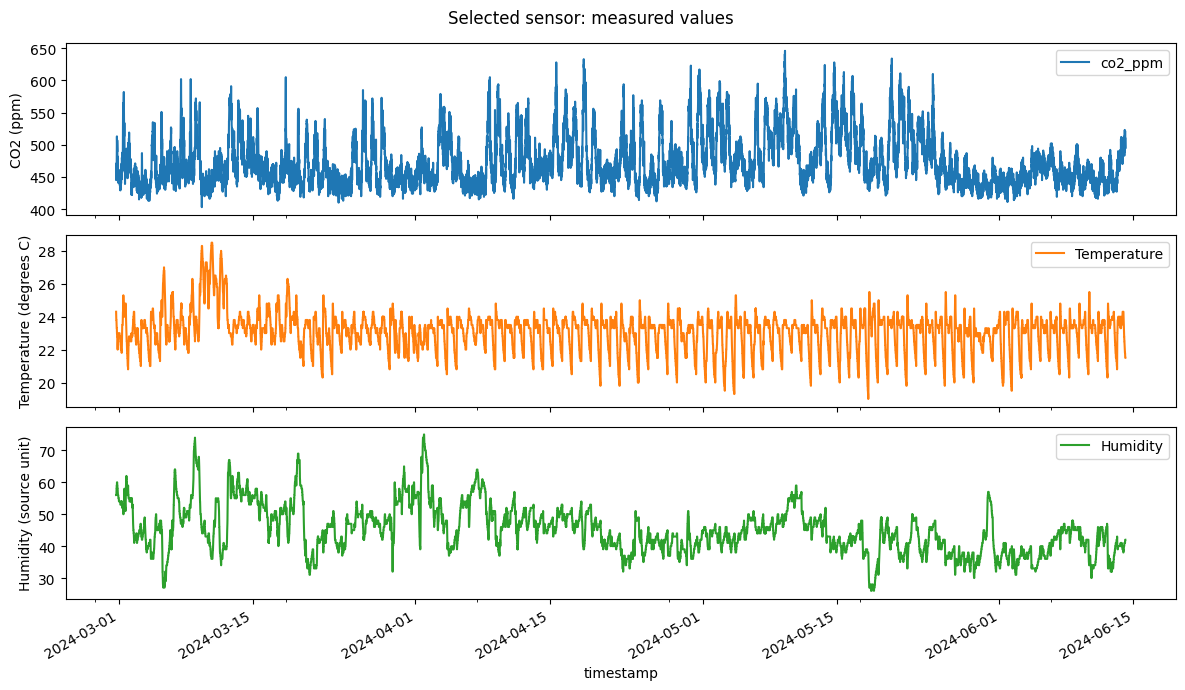

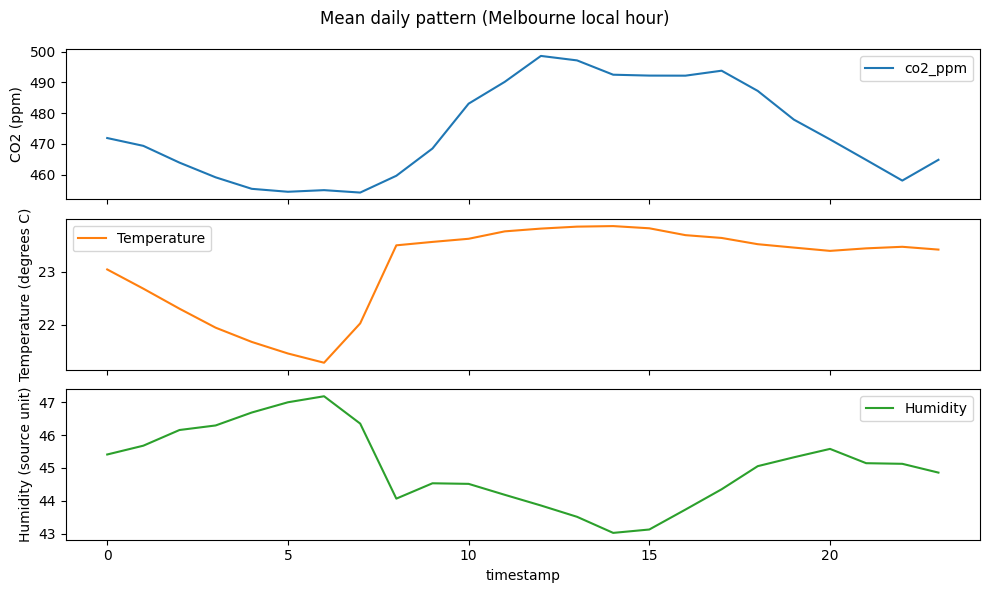

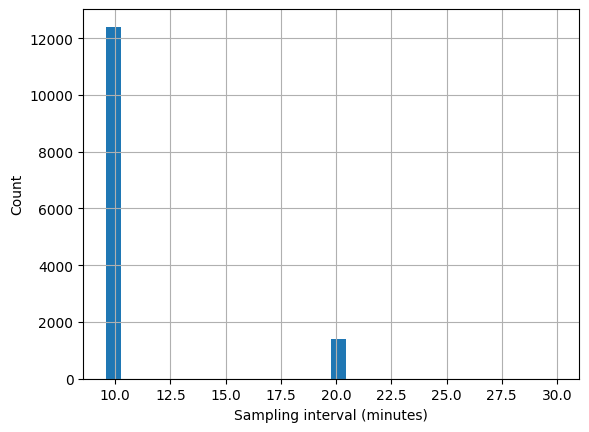

In [5]:
"""Plot observed histories, local-hour averages and sampling intervals.

Uses sensor_series and Melbourne local time for descriptive plots. If matplotlib
is unavailable, prints setup guidance and leaves the analytical workflow usable."""

# Optional visual checks; tables and splits do not require matplotlib.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("For time-series and daily-pattern plots, run %pip install matplotlib, then rerun this cell.")
else:
    # Convert only the plotting copy to Melbourne time; modelling remains in UTC.
    local_series = sensor_series.copy()
    local_series.index = local_series.index.tz_convert("Australia/Melbourne")
    # Plot each variable separately because their units and scales differ.
    axes = local_series[["co2_ppm", "Temperature", "Humidity"]].plot(subplots=True, figsize=(12, 7), title="Selected sensor: measured values")
    for axis, label in zip(axes, ["CO2 (ppm)", "Temperature (degrees C)", "Humidity (source unit)"]):
        axis.set_ylabel(label)
    plt.tight_layout()
    plt.show()
    axes = local_series.groupby(local_series.index.hour)[["co2_ppm", "Temperature", "Humidity"]].mean().plot(subplots=True, figsize=(10, 6), title="Mean daily pattern (Melbourne local hour)")
    for axis, label in zip(axes, ["CO2 (ppm)", "Temperature (degrees C)", "Humidity (source unit)"]):
        axis.set_ylabel(label)
    plt.tight_layout()
    plt.show()
    local_series.index.to_series().diff().dt.total_seconds().div(60).hist(bins=30)
    plt.xlabel("Sampling interval (minutes)")
    plt.ylabel("Count")
    plt.show()


## 4. Feature construction
The selected sensor samples about every 10 minutes. An exact 15-minute measured target is therefore unsupported. Use a **20-minute horizon** with a 2-minute target tolerance, without interpolating targets. Historical CO2 at 10 and 20 minutes ago is matched backward only, allowing 2 minutes of staleness. Compute the rate using actual elapsed time. Review the actual horizon summary below.

Split forecast issue times into approximately 60% training, 20% validation and 20% final test. Purge earlier examples whose target reaches the next period. Historical inputs from a preceding period are available at forecast time and may be used. Tune models on validation only and reserve the final test for the selected configuration. Fit any learned scaling or imputation on training only. Revisit the original 15-minute objective if higher-frequency data becomes available.

## 5. Validation design
The chronological split prevents future information entering training. Boundary purging removes earlier examples whose target reaches into the next period, so the validation and final test periods represent later deployment conditions rather than randomly mixed observations.

In [6]:
"""Build observed future targets, historical features and chronological splits.

Inputs are a single sensor_series. Outputs are forecast_data, train, validation,
test, X_train/X_val/X_test and y_train/y_val/y_test. CO2 is in ppm and its
backward rate is ppm/minute. The 20-minute horizon reflects 10-minute sampling;
2-minute matching tolerance never fills targets. Boundary targets are purged.
Raises ValueError below 100 usable forecasts; asserts nonempty ordered splits."""

# The horizon is chosen to match the approximately 10-minute sampling interval.
HORIZON = pd.Timedelta("20min")
# Matching tolerance accepts nearby measured observations but never interpolates a target.
TOLERANCE = pd.Timedelta("2min")

# The tested helper performs backward-only lag matching and nearest measured-target matching.
from co2_models import build_forecast_features
forecast_data = build_forecast_features(sensor_series, HORIZON, TOLERANCE)

# Diagnose rejected forecasts before dropping rows; categories can overlap.
missing_flags = pd.DataFrame({
    "missing_lag_10min": forecast_data["lag_time_10"].isna(),
    "missing_lag_20min": forecast_data["lag_time_20"].isna(),
    "missing_temperature": forecast_data["Temperature"].isna(),
    "missing_humidity": forecast_data["Humidity"].isna(),
    "missing_target": forecast_data["target_time"].isna() | forecast_data["target_co2_ppm"].isna(),
})
exclusion_diagnostics = pd.DataFrame({
    "condition": missing_flags.columns,
    "rows": [int(missing_flags[column].sum()) for column in missing_flags.columns],
    "share_percent": [100 * missing_flags[column].mean() for column in missing_flags.columns],
})
display(exclusion_diagnostics)
# Keep the feature list explicit so the same inputs are used for every candidate model.
feature_columns = ["co2_ppm", "co2_lag_10min", "co2_lag_20min", "Temperature", "Humidity", "co2_rate_ppm_per_min"]
rows_before = len(forecast_data)
# Remove rows only after recording the overlapping exclusion diagnostics above.
forecast_data = forecast_data.dropna(subset=feature_columns + ["target_time", "target_co2_ppm"]).reset_index(drop=True)
numeric_columns = feature_columns + ["target_co2_ppm"]
if not np.isfinite(forecast_data[numeric_columns].to_numpy(dtype=float)).all():
    raise ValueError("Forecast inputs and targets must be finite after cleaning.")
if not (forecast_data["lag_time_10"] <= forecast_data["issue_time"]).all() or not (forecast_data["lag_time_20"] <= forecast_data["issue_time"]).all():
    raise ValueError("Historical matching selected a measurement after the issue time.")
target_distance = (forecast_data["target_time"] - forecast_data["desired_target_time"]).abs()
if not (target_distance <= TOLERANCE).all():
    raise ValueError("A target falls outside the declared matching tolerance.")
forecast_data["actual_horizon_minutes"] = (forecast_data["target_time"] - forecast_data["issue_time"]).dt.total_seconds() / 60
print(f"Usable forecasts: {len(forecast_data):,}; excluded for missing inputs/targets: {rows_before - len(forecast_data):,}")
display(forecast_data["actual_horizon_minutes"].describe())
if len(forecast_data) < 100:
    raise ValueError("Too few forecasts. Review sensor coverage, lag intervals and target tolerance.")
validation_start = forecast_data["issue_time"].iloc[int(.6 * len(forecast_data))]
test_start = forecast_data["issue_time"].iloc[int(.8 * len(forecast_data))]

# Purge examples whose target extends into the next period to prevent boundary leakage.
train = forecast_data.loc[(forecast_data.issue_time < validation_start) & (forecast_data.target_time < validation_start)].copy()
validation = forecast_data.loc[(forecast_data.issue_time >= validation_start) & (forecast_data.issue_time < test_start) & (forecast_data.target_time < test_start)].copy()
test = forecast_data.loc[forecast_data.issue_time >= test_start].copy()
assert all(len(part) > 0 for part in [train, validation, test])
assert train.target_time.max() < validation.issue_time.min()
assert validation.target_time.max() < test.issue_time.min()
X_train, y_train = train[feature_columns].copy(), train["target_co2_ppm"].copy()
X_val, y_val = validation[feature_columns].copy(), validation["target_co2_ppm"].copy()
X_test, y_test = test[feature_columns].copy(), test["target_co2_ppm"].copy()
split_summary = pd.DataFrame([{"split": name, "rows": len(part), "start": part.issue_time.min(), "last_issue": part.issue_time.max(), "last_target": part.target_time.max()} for name, part in [("train", train), ("validation", validation), ("test", test)]])

display(split_summary)
print("Purged boundary forecasts:", len(forecast_data) - len(train) - len(validation) - len(test))

,condition,rows,share_percent
0,missing_lag_10min,2982,21.608696
1,missing_lag_20min,3439,24.920290
2,missing_temperature,0,0.000000
3,missing_humidity,0,0.000000
4,missing_target,1387,10.050725


Usable forecasts: 7,855; excluded for missing inputs/targets: 5,945


count    7855.000000
mean       19.998994
std         0.015381
min        19.566667
25%        20.000000
50%        20.000000
75%        20.000000
max        20.350000
Name: actual_horizon_minutes, dtype: float64

,split,rows,start,last_issue,last_target
0,train,4712,2024-02-29 06:54:57+00:00,2024-05-08 15:55:29+00:00,2024-05-08 16:15:29+00:00
1,validation,1569,2024-05-08 16:25:29+00:00,2024-05-27 12:35:35+00:00,2024-05-27 12:55:35+00:00
2,test,1571,2024-05-27 13:05:35+00:00,2024-06-13 17:25:44+00:00,2024-06-13 17:45:44+00:00


Purged boundary forecasts: 3


In [7]:
"""Evaluate persistence on training and validation and export reproducible data.

Inputs are the prepared splits and audit tables. Outputs are baseline_results
and CSV files under prepared_data. The test split is exported without scoring.
Exports replace files of the same name and require write access."""

from co2_models import forecast_metrics

# Persistence predicts that the next CO2 value equals the current value.
# Establish the baseline on training/validation; the final test remains reserved.
def persistence_metrics(part):
    """Score the forecast that future CO2 equals current measured CO2.

    Args:
        part (pandas.DataFrame): Nonempty prepared split with numeric
            co2_ppm and target_co2_ppm columns, both in ppm. Call with
            training or validation data during model development.

    Returns:
        dict: MAE_ppm, RMSE_ppm, mean_signed_error_ppm and prediction_seconds.
            Signed error is prediction minus observation; positive means
            overprediction. Timing covers array extraction only, excluding
            error calculations, and is a rough single-call measurement.
            Missing values propagate to metrics; empty inputs yield NaN.

    Raises:
        KeyError: If a required CO2 column is missing.
        TypeError: If column values cannot support numeric arithmetic.

    Examples:
        sample = pd.DataFrame({"co2_ppm": [400., 420.],
        ...                        "target_co2_ppm": [410., 410.]})
        persistence_metrics(sample)["MAE_ppm"]
        10.0
    """
    before = perf_counter()
    prediction = part["co2_ppm"].to_numpy()
    prediction_seconds = perf_counter() - before
    # Positive residuals mean that persistence overpredicts measured CO2.
    metrics = forecast_metrics(part["target_co2_ppm"], prediction)
    metrics["prediction_seconds"] = prediction_seconds
    return metrics
baseline_results = pd.DataFrame({"train": persistence_metrics(train), "validation": persistence_metrics(validation)}).T
display(baseline_results)
# Export reproducible intermediate data next to the notebook; raw files stay in place.
output_dir = data_dir.parent / "prepared_data"
output_dir.mkdir(exist_ok=True)
for name, part in [("train", train), ("validation", validation), ("test", test)]:
    part.to_csv(output_dir / f"{name}.csv", index=False)
sensor_audit.to_csv(output_dir / "sensor_audit.csv", index=False)
period_audit.to_csv(output_dir / "period_audit.csv")
split_summary.to_csv(output_dir / "split_summary.csv", index=False)
exclusion_diagnostics.to_csv(output_dir / "exclusion_diagnostics.csv", index=False)
print("Saved datasets and audit tables to", output_dir)

,MAE_ppm,RMSE_ppm,mean_signed_error_ppm,prediction_seconds
train,10.679754,13.900042,0.03629,0.000096
validation,10.643722,13.830348,-0.06501,0.000080


Saved datasets and audit tables to c:\Users\ezhu2\Documents\MMA3001\MMA3001-Eric-Zhu\prepared_data


## 6. Model development
Use four feature sets: CO2 history; history plus temperature/humidity; environmental history plus the 10-minute rate; and environmental history plus the 20-minute rate. Rates use measured elapsed times. The 20-minute rate is already determined by current/lagged CO2 and elapsed time, so extra information is limited; a rate can still change how a tree partitions the inputs.

Fit ordinary least squares and trees with depths 2, 4, 6, 8 or unlimited and minimum leaf sizes 5, 20 or 50. Select by lowest **validation MAE**, including persistence as a candidate. Compare training/validation error for overfitting. Only after selection, score the frozen training-fit model and persistence on the final test. Re-running is reproducible but must not become test-driven tuning.

Synthetic validation input noise (0, 5, 10 ppm standard deviation) checks sensitivity while keeping measured targets unchanged. Rising-period test diagnostics use the declared historical rate threshold >1 ppm/min. Trees cannot extrapolate beyond training leaf averages. Runtime measurements are single CPU wall-clock measurements, not reliable microbenchmarks. Numerical integration is an optional descriptive extension and is not part of this model comparison.

Selected by validation MAE: linear_history_environment_rate20


,candidate,model,features,max_depth,min_samples_leaf,split,MAE_ppm,RMSE_ppm,mean_signed_error_ppm,fit_seconds,prediction_seconds
0,linear_history_environment_rate20,linear,"co2_ppm, co2_lag_10min, co2_lag_20min, Tempera...",NaN,NaN,validation,10.202764,13.364106,-1.348057,1.438200e-03,0.001039
1,linear_history_environment,linear,"co2_ppm, co2_lag_10min, co2_lag_20min, Tempera...",NaN,NaN,validation,10.204467,13.365890,-1.356358,1.330900e-03,0.000731
2,linear_history_environment_rate10,linear,"co2_ppm, co2_lag_10min, co2_lag_20min, Tempera...",NaN,NaN,validation,10.219889,13.379959,-1.348830,1.500700e-03,0.001042
3,linear_history,linear,"co2_ppm, co2_lag_10min, co2_lag_20min",NaN,NaN,validation,10.238015,13.403486,-1.243765,9.447500e-03,0.000755
4,tree_history_depthNone_leaf50,tree,"co2_ppm, co2_lag_10min, co2_lag_20min",NaN,50.0,validation,10.640446,14.033840,-1.574280,4.388800e-03,0.000828
5,persistence,persistence,co2_ppm,NaN,NaN,validation,10.643722,13.830348,-0.065010,3.000023e-07,0.000018
6,tree_history_depth8_leaf50,tree,"co2_ppm, co2_lag_10min, co2_lag_20min",8.0,50.0,validation,10.645202,14.037047,-1.575267,4.628600e-03,0.000881
7,tree_history_environment_depth6_leaf50,tree,"co2_ppm, co2_lag_10min, co2_lag_20min, Tempera...",6.0,50.0,validation,10.662294,14.004013,-1.645518,5.071700e-03,0.000767
8,tree_history_depth6_leaf50,tree,"co2_ppm, co2_lag_10min, co2_lag_20min",6.0,50.0,validation,10.676131,14.061074,-1.648367,4.244100e-03,0.000978
9,tree_history_depth6_leaf5,tree,"co2_ppm, co2_lag_10min, co2_lag_20min",6.0,5.0,validation,10.681881,13.974064,-1.394657,4.307300e-03,0.000898


split,train,validation
candidate,,
linear_history,10.053632,10.238015
linear_history_environment,10.054196,10.204467
linear_history_environment_rate10,10.051595,10.219889
linear_history_environment_rate20,10.053406,10.202764
persistence,10.679754,10.643722
...,...,...
tree_history_environment_rate20_depth8_leaf5,8.792950,11.951787
tree_history_environment_rate20_depth8_leaf50,9.564944,10.779909
tree_history_environment_rate20_depthNone_leaf20,9.094700,11.012322


,candidate,MAE_ppm,RMSE_ppm,mean_signed_error_ppm,prediction_seconds
0,persistence,8.690643,10.920784,0.176321,0.000018
1,linear_history_environment_rate20,7.832765,9.725016,1.245311,0.000998


,input_noise_std_ppm,MAE_ppm,RMSE_ppm,mean_signed_error_ppm
0,0.0,10.202764,13.364106,-1.348057
1,5.0,10.704624,13.885298,-1.270392
2,10.0,12.065694,15.605939,-1.409201


,target_week,rows,persistence_mae_ppm,selected_mae_ppm,improvement_ppm,improvement_percent
0,2024-W21,547,8.177331,7.449847,0.727483,8.896344
1,2024-W22,618,9.284790,8.269890,1.014900,10.930780
2,2024-W23,406,8.477833,7.683290,0.794543,9.372001


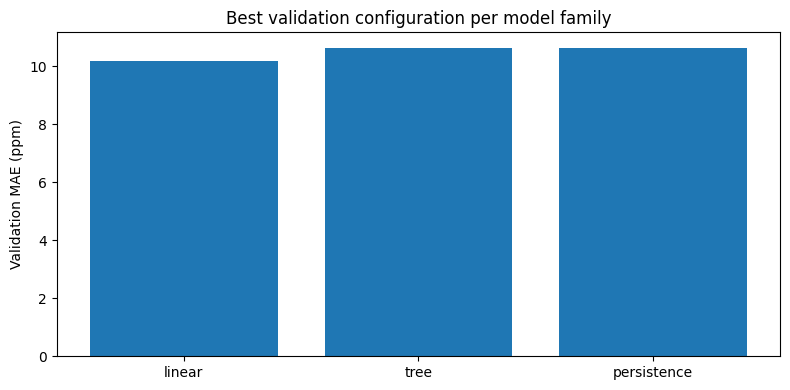

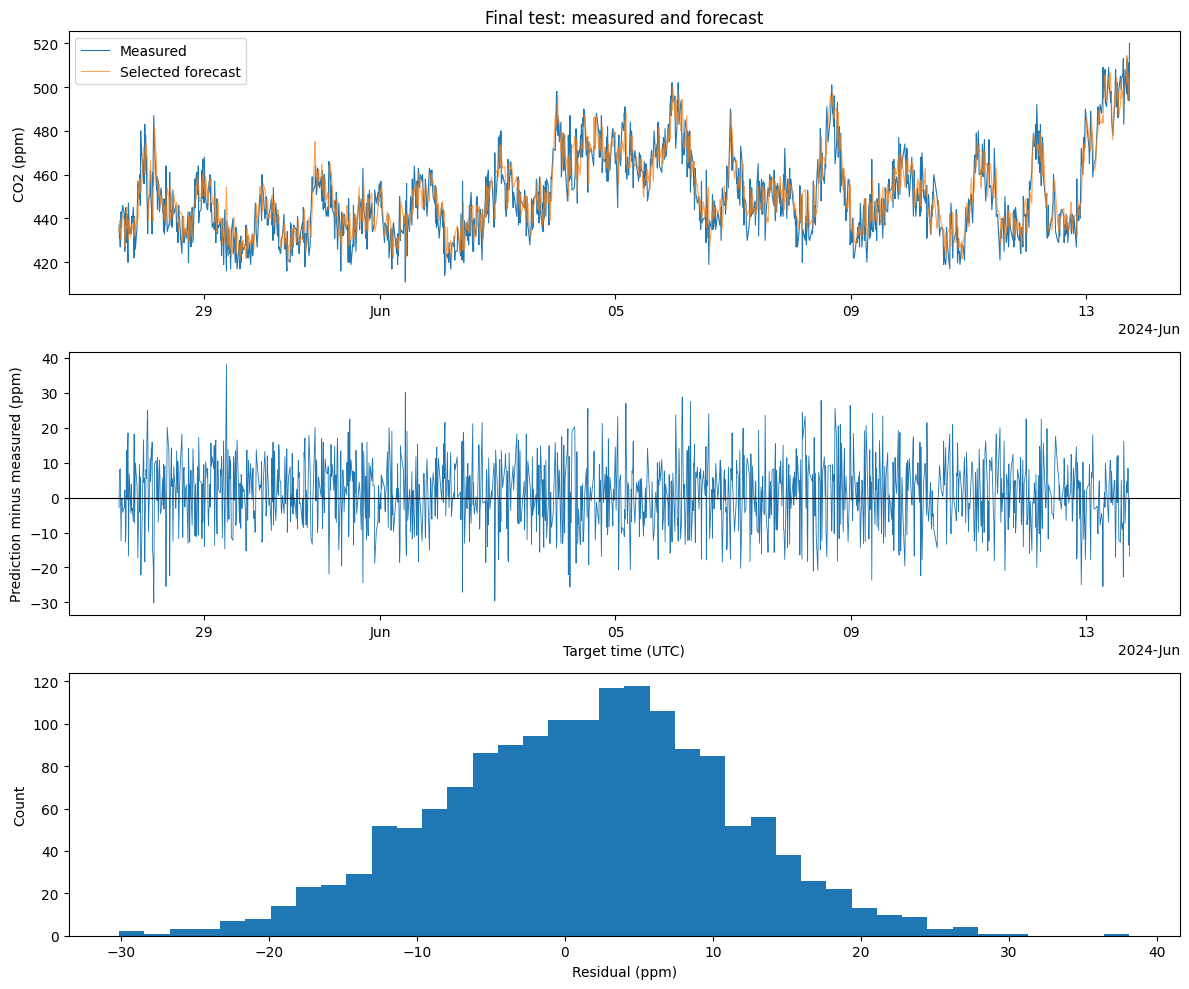

In [8]:
"""Train and validate candidate models, then evaluate the frozen selection.

Requires prepared train/validation/test from the preceding cells and
scikit-learn. Writes experiments, predictions and metrics to model_results.
"""
# Compare all candidates using validation MAE; the test split is scored only after selection.
from co2_models import compare_models, plot_model_results
model_output_dir = data_dir.parent / "model_results"
comparison = compare_models(train, validation, test, model_output_dir)
print("Selected by validation MAE:", comparison["selected_name"])
display(comparison["ranking"].head(12))
# Compare training and validation errors to reveal complexity-related overfitting.
complexity_results = comparison["experiments"].pivot(index="candidate", columns="split", values="MAE_ppm")
display(complexity_results)
# These tables report frozen-test performance and synthetic validation-noise sensitivity.
display(comparison["test_metrics"], comparison["noise_sensitivity"])
# Paired weekly errors assess whether the frozen test improvement is consistent.
display(comparison["test_error_by_week"])
try:
    # Plot files are optional; model metrics remain available without matplotlib.
    plot_model_results(comparison, model_output_dir)
except ImportError:
    print("Optional plots skipped. Install matplotlib to generate them.")

## 7. Results
The model-comparison cell displays validation rankings, final-test metrics and diagnostic plots. Interpret MAE and RMSE as average ppm errors; use signed error separately to discuss bias.

## 8. Sensitivity and performance
The comparison includes feature-set experiments, tree settings, synthetic input-noise experiments and timing outputs. Treat timing as single-run engineering evidence rather than a formal benchmark.

## 9. Engineering discussion and limitations
This workflow evaluates one sensor and one contiguous period. Predictions are intended as supplementary monitoring evidence. They do not establish causal ventilation effects, sensor calibration, health thresholds or generalisation to other rooms and seasons.

## 10. Conclusion
Use the frozen final-test comparison to answer whether the selected model improves on persistence for the 20-minute question. Realistic improvements include resolving room mapping, evaluating more sensors and seasons, collecting higher-frequency data and validating uncertainty.

## 11. AI-use reflection and references
Record where AI assisted with loading, auditing, modelling, debugging or documentation. Add your own contribution estimate, rejected or verified suggestions, and the sources used for the dataset, project brief, teaching notes and methodology.

## 12. Repository and submission materials
Before submission, rerun the notebook from top to bottom, run the tests and doctest, regenerate the HTML documentation, check dependencies and README instructions, and confirm that the required report, repository link, archive and presentation materials are complete.